I will generate data up to wave number:  355.55555555555554
it took me  0.8571350574493408  s to generate the isotropic turbulence.
mean u =  -2.568379066381358e-08
k =  0
k =  1
k =  2
k =  3
k =  4
k =  5
k =  6
k =  7
k =  8
k =  9
k =  10
k =  11
k =  12
k =  13
k =  14
k =  15
k =  16
k =  17
k =  18
k =  19
k =  20
k =  21
k =  22
k =  23
k =  24
k =  25
k =  26
k =  27
k =  28
k =  29
k =  30
k =  31
k =  32
k =  31
k =  30
k =  29
k =  28
k =  27
k =  26
k =  25
k =  24
k =  23
k =  22
k =  21
k =  20
k =  19
k =  18
k =  17
k =  16
k =  15
k =  14
k =  13
k =  12
k =  11
k =  10
k =  9
k =  8
k =  7
k =  6
k =  5
k =  4
k =  3
k =  2
k =  1
k =  1
k =  1
k =  2
k =  3
k =  4
k =  5
k =  6
k =  7
k =  8
k =  9
k =  10
k =  11
k =  12
k =  13
k =  14
k =  15
k =  16
k =  17
k =  18
k =  19
k =  20
k =  21
k =  22
k =  23
k =  24
k =  25
k =  26
k =  27
k =  28
k =  29
k =  30
k =  31
k =  32
k =  31
k =  30
k =  29
k =  28
k =  27
k =  26
k =  25
k =  24
k =  23
k =  22
k =  21


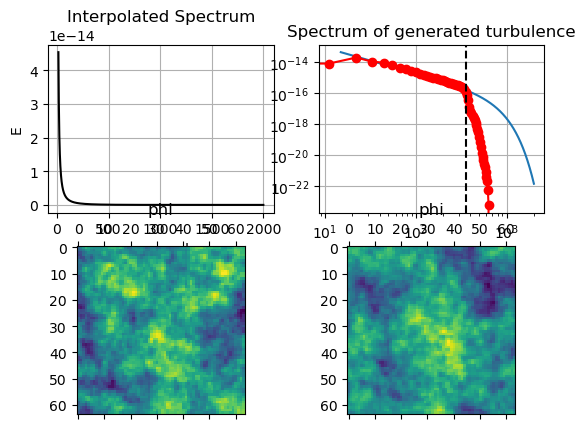

In [23]:
# -*- coding: utf-8 -*-
"""
Created on Saturday March 7 06:08:01 2026

@author: Tony Saad
"""
# !/usr/bin/env python
from scipy import interpolate
import numpy as np
from numpy import pi, exp
import time
import scipy.io
from tkespec import compute_tke_spectrum_1d
import isoturb
import isoturbo
import matplotlib.pyplot as plt
from fileformats import FileFormats
import isoio
plt.interactive(True)

# load an experimental specturm. Alternatively, specify it via a function call
cbcspec = np.loadtxt('cbc_spectrum.txt')
kcbc = cbcspec[:, 0] * 100
ecbc = cbcspec[:, 1] * 1e-6
especf = interpolate.interp1d(kcbc, ecbc, 'cubic')


def cbc_spec(k):
    return especf(k)


# theoretical spectra
def karman_spec(k):
    nu = 1.0e-5
    alpha = 1.452762113
    urms = 0.25
    ke = 40.0
    kappae = np.sqrt(5.0 / 12.0) * ke
    L = 0.746834 / kappae  # integral length scale - sqrt(Pi)*Gamma(5/6)/Gamma(1/3)*1/ke
    #  L = 0.05 # integral length scale
    #  Kappae = 0.746834/L
    epsilon = urms * urms * urms / L
    kappaeta = pow(epsilon, 0.25) * pow(nu, -3.0 / 4.0)
    r1 = k / kappae
    r2 = k / kappaeta
    espec = alpha * urms * urms / kappae * pow(r1, 4) / pow(1.0 + r1 * r1, 17.0 / 6.0) * np.exp(-2.0 * r2 * r2)
    return espec


def power_spec(k):
    Nu = 1 * 1e-3
    L = 0.1
    Li = 1
    ch = 1
    cl = 10
    p0 = 8
    c0 = pow(10, 2)
    Beta = 2
    Eta = Li / 20.0
    ES = Nu * Nu * Nu / (Eta * Eta * Eta * Eta)
    x = k * Eta
    fh = np.exp(-Beta * pow(pow(x, 4) + pow(ch, 4), 0.25) - ch)
    x = k * L
    fl = pow(x / pow(x * x + cl, 0.5), 5.0 / 3.0 + p0)
    espec = c0 * pow(k, -5.0 / 3.0) * pow(ES, 2.0 / 3.0) * fl * fh
    return espec

# atmospheric turbulence
def tatarskii_spec(k):
    """
    Cn2: Structure constant (strength of turbulence)
    L0: Outer scale (size of largest eddies)
    l0: Inner scale (size of smallest eddies)
    """

    # Physical Constants for Stratosphere
    Cn2 = 1e-11       # Refractive index structure constant
    L0  = 100.0       # Outer scale (meters)
    l0  = 0.01        # Inner scale (meters)
    
    # Derived parameters
    k0 = 2.0 * np.pi / L0
    km = 5.92 / l0
    
    # 3D Power Spectral Density (Tatarskii)
    # The 0.033 is the Kolmogorov constant for scalars
    phi_n = 0.033 * Cn2 * np.power(k**2 + k0**2, -11/6) * np.exp(-(k**2) / (km**2))
    
    # Convert 3D PSD to the 1D Energy Spectrum E(k) 
    # This is what your 'um = sqrt(espec * dkn)' logic expects
    espec = 4.0 * np.pi * k**2 * phi_n
    
    return espec    
# ----------------------------------------------------------------------------------------------
# __    __   ______   ________  _______         ______  __    __  _______   __    __  ________
# |  \  |  \ /      \ |        \|       \       |      \|  \  |  \|       \ |  \  |  \|        \
# | $$  | $$|  $$$$$$\| $$$$$$$$| $$$$$$$\       \$$$$$$| $$\ | $$| $$$$$$$\| $$  | $$ \$$$$$$$$
# | $$  | $$| $$___\$$| $$__    | $$__| $$        | $$  | $$$\| $$| $$__/ $$| $$  | $$   | $$
# | $$  | $$ \$$    \ | $$  \   | $$    $$        | $$  | $$$$\ $$| $$    $$| $$  | $$   | $$
# | $$  | $$ _\$$$$$$\| $$$$$   | $$$$$$$\        | $$  | $$\$$ $$| $$$$$$$ | $$  | $$   | $$
# | $$__/ $$|  \__| $$| $$_____ | $$  | $$       _| $$_ | $$ \$$$$| $$      | $$__/ $$   | $$
# \$$    $$ \$$    $$| $$     \| $$  | $$      |   $$ \| $$  \$$$| $$       \$$    $$   | $$
#  \$$$$$$   \$$$$$$  \$$$$$$$$ \$$   \$$       \$$$$$$ \$$   \$$ \$$        \$$$$$$     \$$
# ----------------------------------------------------------------------------------------------

# specify whether you want to use threads or not to generate turbulence
use_parallel = False
patches = [1, 1, 8]
filespec = 'cbc'
whichspec = tatarskii_spec

# set the number of modes you want to use to represent the velocity.
nmodes = 500
N = 64

# write to file
enableIO = False  # enable writing to file
fileformat = FileFormats.FLAT  # Specify the file format supported formats are: FLAT, IJK, XYZ

# save the velocity field as a matlab matrix (.mat)
savemat = False

# compute the mean of the fluctuations for verification purposes
computeMean = True

# input domain size in the x, y, and z directions. This value is typically
# based on the largest length scale that your data has. For the cbc data,
# the largest length scale corresponds to a wave number of 15, hence, the
# domain size is L = 2pi/15.
lx = 9 * 2.0 * pi / 100.0
ly = 9 * 2.0 * pi / 100.0
lz = 9 * 2.0 * pi / 100.0

# input number of cells (cell centered control volumes). This will
# determine the maximum wave number that can be represented on this grid.
# see wnn below
nx = N  # number of cells in the x direction
ny = N  # number of cells in the y direction
nz = N  # number of cells in the z direction

# enter the smallest wavenumber represented by this spectrum
wn1 = 15  # determined here from cbc spectrum properties

# ------------------------------------------------------------------------------
# END USER INPUT
# ------------------------------------------------------------------------------
t0 = time.time()
phi = isoturb.generate_scalar_isotropic_turbulence(lx, ly, lz, nx, ny, nz, nmodes, wn1, whichspec)
# phi = isoturb.generate_periodic_scalar_turbulence(lx, ly, lz, nx, ny, nz, nmodes, wn1, whichspec)

t1 = time.time()
print('it took me ', t1 - t0, ' s to generate the isotropic turbulence.')

dx = lx / nx
dy = ly / ny
dz = lz / nz

#isoio.writefile('u.txt', 'x', dx, dy, dz, u, fileformat)

# if savemat:
#     data = {}  # CREATE empty dictionary
#     data['U'] = u
#     data['V'] = v
#     data['W'] = w
#     scipy.io.savemat('uvw.mat', data)

# compute mean velocities
if computeMean:
    phimean = np.mean(phi)
    print('mean u = ', phimean)

    phifluc = phimean - phi

    # print
    # 'mean u fluct = ', np.mean(ufluc)

    phifrms = np.mean(phifluc * phifluc)

    # print
    # 'u fluc rms = ', np.sqrt(ufrms)
    # print
    # 'v fluc rms = ', np.sqrt(vfrms)
    # print
    # 'w fluc rms = ', np.sqrt(wfrms)

# verify that the generated velocities fit the spectrum
knyquist, wavenumbers, tkespec = compute_tke_spectrum_1d(phi, lx, ly, lz, True)

# compare spectra
# integral comparison:
# find index of nyquist limit
idx = (np.where(wavenumbers == knyquist)[0][0]) - 1

km0 = 2.0 * np.pi / lx
nmodes = 5000
dk0 = (knyquist - km0) / nmodes
exactRange = km0 + np.arange(0, nmodes + 1) * dk0
exactE = np.trapz(karman_spec(exactRange), dx=dk0)
numE = np.trapz(tkespec[0:idx], dx=wavenumbers[0])
# print
# 'diff = ', abs(exactE - numE) / exactE * 100

# analyze how well we fit the input spectrum
# espec = cbc_spec(kcbc) # compute the cbc original spec

# compute the RMS error committed by the generated spectrum
# find index of nyquist limit
idx = (np.where(wavenumbers == knyquist)[0][0]) - 1
exact = whichspec(wavenumbers[4:idx])
num = tkespec[4:idx]
diff = np.abs((exact - num) / exact)
meanE = np.mean(diff)
# print('got here ')
# print
# 'Mean Error = ', meanE * 100.0, '%'
# rmsE = np.sqrt(np.mean(diff * diff))
# print
# 'RMS Error = ', rmsE * 100, '%'

# np.savetxt('tkespec_' + filespec + '_' + str(N) + '.txt',np.transpose([wavenumbers,tkespec]))



# fig = plt.figure(figsize=(3.5, 2.6), dpi=100)
# plt.rc("font", size=10, family='serif')

wnn = np.arange(wn1, 2000)
# l1, = plt.loglog(kcbc,ecbc, 'k-', label='input')
# plt.loglog(wnn, whichspec(wnn), 'k-', label='input')
# l2, = plt.loglog(wavenumbers, tkespec, 'bo-', markersize=4, markerfacecolor='w', markevery=1, label='computed')

# plt.axis([8, 10000, 1e-7, 1e-2])
# # plt.xticks(fontsize=12)
# # plt.yticks(fontsize=12)
# plt.axvline(x=knyquist, linestyle='--', color='black')
# plt.xlabel('$\kappa$ (1/m)')
# plt.ylabel('$E(\kappa)$ (m$^3$/s$^2$)')
# plt.grid()
# plt.gcf().tight_layout()
# # plt.title(str(N)+'$^3$')
# # plt.legend(handles=[l1,l2],loc=3)
# # fig.savefig('tkespec_' + filespec + '_' + str(N) + '.pdf')
#


q, ((p1,p2),(p3,p4)) = plt.subplots(2,2)
# print(np.std(phi))
# p1.plot(kcbc, ecbc, 'ob', kcbc, ecbc, '-')
p1.plot(wnn, whichspec(wnn), 'k-', label='input')
p1.set_title('Interpolated Spectrum')
p1.grid()
p1.set_xlabel('wave number')
p1.set_ylabel('E')

p2.loglog(wnn, whichspec(wnn), '-', wavenumbers, tkespec, 'ro-')
p2.axvline(x=knyquist, linestyle='--', color='black')
p2.set_title('Spectrum of generated turbulence')
p2.grid()

# contour plot
p3.matshow(phi[:,:,nz//2])
p3.set_title('phi')

p4.matshow(phi[:,ny//2,:])
p4.set_title('phi')
# #
plt.show()

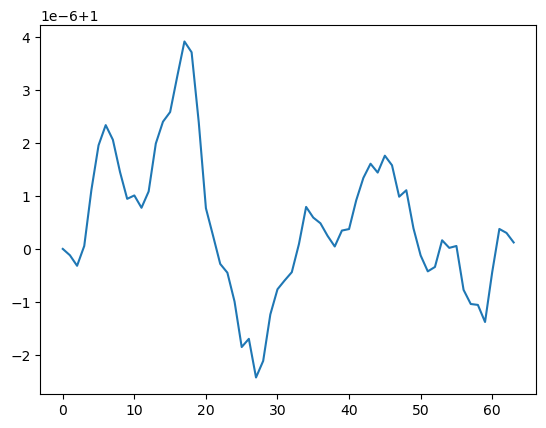

In [24]:
plt.plot(phi[:,ny//3,nz//2]+1.0)